# Лабораторна робота №4
## Дерева рішень та ансамблеве машинне навчання

**Мета:** виконати побудову, навчання та оцінювання моделей Decision Tree, Random Forest та Gradient Boosting; дослідити особливості їх роботи, порівняти якість прогнозування та інтерпретувати внесок ознак за допомогою feature importance.

Використано набір даних з ЛР1 - **Telco Customer Churn**. Задача - класифікація: цільова змінна `Churn` показує, чи пішов клієнт (1) чи залишився (0), так само як у ЛР3.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

## 1. Завантаження та підготовка даних

In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Кількість записів:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

Кількість записів: 7043
Кількість стовпців: 21


In [3]:
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Кількість дублікатів:", df.duplicated().sum())
df = df.drop_duplicates()

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("Кількість записів після очищення:", len(df))

Кількість дублікатів: 22
Кількість записів після очищення: 7021


Очищення таке саме, як у ЛР1 і ЛР3: видалено `customerID`, `TotalCharges` перетворено в число, видалено дублікати, `Churn` закодовано як 1/0.

## 2. Початковий аналіз даних

In [4]:
print("Кількість об'єктів:", df.shape[0])
print("Кількість вхідних ознак:", df.shape[1] - 1)

Кількість об'єктів: 7021
Кількість вхідних ознак: 19


In [5]:
types_table = pd.DataFrame({
    "Ознака": df.columns,
    "Тип даних": df.dtypes.astype(str).values
})
types_table

,Ознака,Тип даних
0,gender,object
1,SeniorCitizen,int64
2,Partner,object
3,Dependents,object
4,tenure,int64
5,PhoneService,object
6,MultipleLines,object
7,InternetService,object
8,OnlineSecurity,object
9,OnlineBackup,object


In [6]:
missing_table = pd.DataFrame({
    "Кількість пропусків": df.isnull().sum(),
    "Частка, %": (df.isnull().mean() * 100).round(2)
})
missing_table[missing_table["Кількість пропусків"] > 0]

,Кількість пропусків,"Частка, %"
TotalCharges,11,0.16


In [7]:
class_table = pd.DataFrame({
    "Кількість": df["Churn"].value_counts(),
    "Частка": df["Churn"].value_counts(normalize=True).round(3)
})
class_table

,Кількість,Частка
Churn,,
0,5164,0.736
1,1857,0.264


In [8]:
y = df["Churn"]
X = df.drop(columns=["Churn"])

categorical_columns = list(X.select_dtypes(include="object").columns)
numeric_columns = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)
print("Категоріальні ознаки:", len(categorical_columns))
print("Числові ознаки:", numeric_columns)

Розмір X: (7021, 19)
Розмір y: (7021,)
Категоріальні ознаки: 15
Числові ознаки: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


Після очищення маємо 7021 об'єкт і 19 вхідних ознак: 15 категоріальних (текстових) і 4 числові (`SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges`). Пропуски є тільки в `TotalCharges` (11 значень, 0.16%), їх заповнимо медіаною після поділу. Класи незбалансовані: 5164 клієнти залишились (73.6%) і 1857 пішли (26.4%). Тому, як і в ЛР3, моделі порівнюємо за F1-score для класу 1, а поділ робимо стратифікованим.

## 3. Поділ на навчальну, валідаційну та тестову вибірки

In [9]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.15 / 0.85, random_state=42, stratify=y_train_val
)

print("Навчальна вибірка:", X_train.shape)
print("Валідаційна вибірка:", X_val.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (4914, 19)
Валідаційна вибірка: (1053, 19)
Тестова вибірка: (1054, 19)


In [10]:
split_table = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True).round(3),
    "Validation": y_val.value_counts(normalize=True).round(3),
    "Test": y_test.value_counts(normalize=True).round(3)
})
split_table

,Train,Validation,Test
Churn,,,
0,0.735,0.736,0.735
1,0.265,0.264,0.265


In [11]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

X_train = X_train.copy()
X_val = X_val.copy()
X_test = X_test.copy()

imputer = SimpleImputer(strategy="median")
imputer.fit(X_train[["TotalCharges"]])

X_train[["TotalCharges"]] = imputer.transform(X_train[["TotalCharges"]])
X_val[["TotalCharges"]] = imputer.transform(X_val[["TotalCharges"]])
X_test[["TotalCharges"]] = imputer.transform(X_test[["TotalCharges"]])

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoder.fit(X_train[categorical_columns])
encoded_columns = encoder.get_feature_names_out(categorical_columns)

X_train_encoded = pd.DataFrame(encoder.transform(X_train[categorical_columns]), columns=encoded_columns, index=X_train.index)
X_val_encoded = pd.DataFrame(encoder.transform(X_val[categorical_columns]), columns=encoded_columns, index=X_val.index)
X_test_encoded = pd.DataFrame(encoder.transform(X_test[categorical_columns]), columns=encoded_columns, index=X_test.index)

X_train_ready = pd.concat([X_train[numeric_columns], X_train_encoded], axis=1)
X_val_ready = pd.concat([X_val[numeric_columns], X_val_encoded], axis=1)
X_test_ready = pd.concat([X_test[numeric_columns], X_test_encoded], axis=1)

print("Медіана TotalCharges з train:", imputer.statistics_[0])
print("Ознак після кодування:", X_train_ready.shape[1])
print("Пропусків:", X_train_ready.isnull().sum().sum(), X_val_ready.isnull().sum().sum(), X_test_ready.isnull().sum().sum())

Медіана TotalCharges з train: 1396.65
Ознак після кодування: 45
Пропусків: 0 0 0


Дані поділено 70/15/15 зі `stratify`: 4914 записів у train, 1053 у validation, 1054 у test. Частка класу 1 у всіх вибірках 0.264-0.265. Це ті самі вибірки, що в ЛР3, тому результати можна порівнювати.

Пропуски `TotalCharges` заповнено медіаною з train (1396.65), текстові ознаки закодовано One-Hot. Імпутер і енкодер навчені тільки на train. Після обробки маємо 45 ознак без пропусків.

**Масштабування не виконується.** Дерево ділить дані умовами виду «`tenure` <= 12», тобто порівнює значення однієї ознаки з порогом. Якщо всі значення ознаки помножити чи зсунути, поріг просто зсунеться разом з ними, і розбиття вийде те саме. Тому для дерев і ансамблів на їх основі масштаб ознак не впливає на результат.

## 4. Decision Tree

In [12]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

default_tree = DecisionTreeClassifier(random_state=42)
default_tree.fit(X_train_ready, y_train)

print("Глибина дерева:", default_tree.get_depth())
print("Кількість листків:", default_tree.get_n_leaves())
print("F1 на train:", round(f1_score(y_train, default_tree.predict(X_train_ready)), 3))
print("F1 на validation:", round(f1_score(y_val, default_tree.predict(X_val_ready)), 3))

Глибина дерева: 26
Кількість листків: 950
F1 на train: 0.998
F1 на validation: 0.497


Дерево без обмежень виросло до глибини 26 і має 950 листків. На навчальній вибірці F1 = 0.998, тобто дерево майже ідеально «запам'ятало» train, а на валідаційній лише 0.497. Це класичне перенавчання: дерево ділить дані доти, доки в кожному листку не залишаться об'єкти одного класу, і так вивчає навіть шум.

## 5. Вплив параметрів дерева рішень

In [13]:
from itertools import product

depth_values = [3, 5, 7, 10, 15, None]
split_values = [2, 10, 20]
leaf_values = [1, 5, 10]

tree_results = []
tree_models = []

for depth, split, leaf in product(depth_values, split_values, leaf_values):
    model = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_split=split,
        min_samples_leaf=leaf,
        random_state=42
    )
    model.fit(X_train_ready, y_train)
    val_pred = model.predict(X_val_ready)
    tree_results.append({
        "max_depth": depth,
        "min_samples_split": split,
        "min_samples_leaf": leaf,
        "F1 Validation": f1_score(y_val, val_pred)
    })
    tree_models.append(model)

tree_results = pd.DataFrame(tree_results)
best_index = tree_results["F1 Validation"].idxmax()
best_tree = tree_models[best_index]

print("Кількість перевірених варіантів:", len(tree_results))
print("Найкращі параметри:", best_tree.get_params()["max_depth"], best_tree.get_params()["min_samples_split"], best_tree.get_params()["min_samples_leaf"])
tree_results.sort_values("F1 Validation", ascending=False).head(10).round(3)

Кількість перевірених варіантів: 54
Найкращі параметри: 5 2 1


,max_depth,min_samples_split,min_samples_leaf,F1 Validation
16,5.0,20,5,0.577
13,5.0,10,5,0.577
10,5.0,2,5,0.577
11,5.0,2,10,0.577
12,5.0,10,1,0.577
9,5.0,2,1,0.577
17,5.0,20,10,0.577
14,5.0,10,10,0.577
15,5.0,20,1,0.577
53,NaN,20,10,0.546


Перевірено 54 комбінації параметрів. Найкращий F1 на валідації 0.577 при `max_depth = 5`. Цікаво, що всі 9 комбінацій з глибиною 5 дають однаковий результат: дерево глибини 5 має лише 31 листок, вузли в ньому великі, і обмеження `min_samples_split` до 20 та `min_samples_leaf` до 10 просто не спрацьовують. Тому вирішальний параметр тут саме глибина. Для дерева без обмеження глибини найкращий результат лише 0.546 (при `min_samples_split = 20`, `min_samples_leaf = 10`): ці параметри трохи стримують перенавчання, але гірше, ніж обмеження глибини. У виводі як найкращі вказано 5, 2, 1 - це перший з однакових варіантів.

## 6. Аналіз перенавчання Decision Tree

In [14]:
overfit_table = []

for name, model in [("Дерево без обмежень", default_tree), ("Найкраще дерево", best_tree)]:
    overfit_table.append({
        "Модель": name,
        "Accuracy train": accuracy_score(y_train, model.predict(X_train_ready)),
        "Accuracy val": accuracy_score(y_val, model.predict(X_val_ready)),
        "F1 train": f1_score(y_train, model.predict(X_train_ready)),
        "F1 val": f1_score(y_val, model.predict(X_val_ready))
    })

pd.DataFrame(overfit_table).round(3)

,Модель,Accuracy train,Accuracy val,F1 train,F1 val
0,Дерево без обмежень,0.999,0.726,0.998,0.497
1,Найкраще дерево,0.804,0.787,0.607,0.577


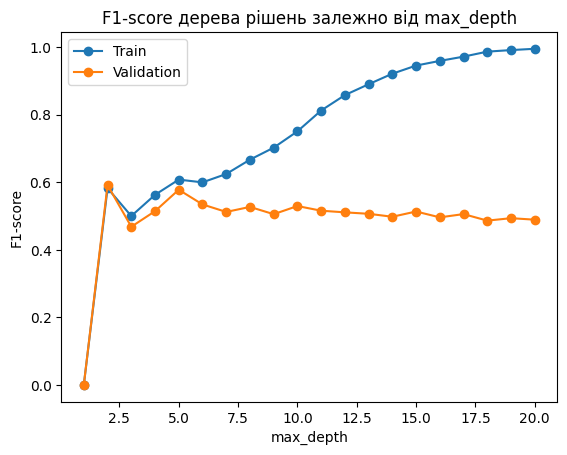

In [15]:
depth_range = range(1, 21)
train_scores = []
val_scores = []

for depth in depth_range:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train_ready, y_train)
    train_scores.append(f1_score(y_train, model.predict(X_train_ready)))
    val_scores.append(f1_score(y_val, model.predict(X_val_ready)))

plt.plot(depth_range, train_scores, marker="o", label="Train")
plt.plot(depth_range, val_scores, marker="o", label="Validation")
plt.title("F1-score дерева рішень залежно від max_depth")
plt.xlabel("max_depth")
plt.ylabel("F1-score")
plt.legend()
plt.show()

Таблиця показує різницю між train і val. У дерева без обмежень Accuracy 0.999 на train і 0.726 на val, F1 0.998 і 0.497, тобто різниця величезна. У найкращого дерева (глибина 5) Accuracy 0.804 і 0.787, F1 0.607 і 0.577, різниця лише 0.03. Обмеження глибини практично прибрало перенавчання.

На графіку це видно ще краще. Лінія train з ростом глибини піднімається майже до 1, а лінія validation після глибини 2-5 перестає рости і тримається близько 0.49-0.53. Чим глибше дерево, тим більший розрив між лініями, тобто тим сильніше перенавчання. При глибині 1 F1 дорівнює 0: дерево з одним розбиттям усіх відносить до класу 0. При глибині 2 F1 на валідації навіть трохи вищий (0.59), але таке дерево має лише 4 листки і дуже грубе правило, а вже при глибині 3 F1 падає до 0.47. Тому малі глибини нестабільні, і глибина 5 є розумним компромісом.

## 7. Random Forest

In [16]:
from sklearn.ensemble import RandomForestClassifier

default_rf = RandomForestClassifier(random_state=42, n_jobs=-1)
default_rf.fit(X_train_ready, y_train)

print("Кількість дерев:", default_rf.n_estimators)
print("F1 на train:", round(f1_score(y_train, default_rf.predict(X_train_ready)), 3))
print("F1 на validation:", round(f1_score(y_val, default_rf.predict(X_val_ready)), 3))

Кількість дерев: 100
F1 на train: 0.998
F1 на validation: 0.505


Random Forest за замовчуванням - це 100 дерев без обмеження глибини. На train F1 = 0.998, на validation 0.505. Кожне окреме дерево тут перенавчене, і усереднення 100 таких дерев результат майже не рятує.

## 8. Вплив параметрів Random Forest

In [17]:
n_values = [100, 200]
depth_values = [5, 10, None]
features_values = ["sqrt", "log2"]

rf_results = []
rf_models = []

for n, depth, features in product(n_values, depth_values, features_values):
    model = RandomForestClassifier(
        n_estimators=n,
        max_depth=depth,
        max_features=features,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train_ready, y_train)
    val_pred = model.predict(X_val_ready)
    rf_results.append({
        "n_estimators": n,
        "max_depth": depth,
        "max_features": features,
        "F1 Validation": f1_score(y_val, val_pred)
    })
    rf_models.append(model)

rf_results = pd.DataFrame(rf_results)
best_index = rf_results["F1 Validation"].idxmax()
best_rf = rf_models[best_index]

print("Найкращі параметри Random Forest:")
print("n_estimators =", best_rf.n_estimators)
print("max_depth =", best_rf.max_depth)
print("max_features =", best_rf.max_features)
rf_results.sort_values("F1 Validation", ascending=False).round(3)

Найкращі параметри Random Forest:
n_estimators = 100
max_depth = 10
max_features = log2


,n_estimators,max_depth,max_features,F1 Validation
3,100,10.0,log2,0.555
9,200,10.0,log2,0.554
8,200,10.0,sqrt,0.544
2,100,10.0,sqrt,0.542
11,200,NaN,log2,0.509
6,200,5.0,sqrt,0.508
0,100,5.0,sqrt,0.507
10,200,NaN,sqrt,0.506
4,100,NaN,sqrt,0.505
5,100,NaN,log2,0.499


Найкраща конфігурація: 100 дерев, `max_depth = 10`, `max_features = "log2"`, F1 на валідації 0.555. Головний параметр тут теж глибина: з глибиною 10 F1 становить 0.542-0.555. Без обмеження глибини F1 близько 0.50-0.51, бо дерева перенавчаються. З глибиною 5 F1 0.49-0.51, бо дерева занадто прості й ліс знаходить мало клієнтів класу 1. Кількість дерев (100 чи 200) майже не впливає: після певної кількості нові дерева вже нічого не додають. `log2` (розглядати менше ознак у кожному вузлі) трохи кращий за `sqrt`, бо дерева виходять різноманітнішими.

## 9. Gradient Boosting

In [18]:
from sklearn.ensemble import GradientBoostingClassifier

default_gb = GradientBoostingClassifier(random_state=42)
default_gb.fit(X_train_ready, y_train)

print("Кількість дерев:", default_gb.n_estimators)
print("F1 на train:", round(f1_score(y_train, default_gb.predict(X_train_ready)), 3))
print("F1 на validation:", round(f1_score(y_val, default_gb.predict(X_val_ready)), 3))

Кількість дерев: 100
F1 на train: 0.652
F1 на validation: 0.555


Gradient Boosting за замовчуванням (100 дерев глибини 3, learning_rate 0.1) одразу дає F1 0.555 на валідації і лише 0.652 на train. На відміну від лісу, тут дерева неглибокі, і модель не перенавчається.

## 10. Вплив параметрів Gradient Boosting

In [19]:
n_values = [50, 100, 200]
learning_rates = [0.05, 0.1]
depth_values = [2, 3]

gb_results = []
gb_models = []

for n, lr, depth in product(n_values, learning_rates, depth_values):
    model = GradientBoostingClassifier(
        n_estimators=n,
        learning_rate=lr,
        max_depth=depth,
        random_state=42
    )
    model.fit(X_train_ready, y_train)
    val_pred = model.predict(X_val_ready)
    gb_results.append({
        "n_estimators": n,
        "learning_rate": lr,
        "max_depth": depth,
        "F1 Validation": f1_score(y_val, val_pred)
    })
    gb_models.append(model)

gb_results = pd.DataFrame(gb_results)
best_index = gb_results["F1 Validation"].idxmax()
best_gb = gb_models[best_index]

print("Найкращі параметри Gradient Boosting:")
print("n_estimators =", best_gb.n_estimators)
print("learning_rate =", best_gb.learning_rate)
print("max_depth =", best_gb.max_depth)
gb_results.sort_values("F1 Validation", ascending=False).round(3)

Найкращі параметри Gradient Boosting:
n_estimators = 200
learning_rate = 0.1
max_depth = 2


,n_estimators,learning_rate,max_depth,F1 Validation
10,200,0.10,2,0.574
9,200,0.05,3,0.563
8,200,0.05,2,0.561
11,200,0.10,3,0.561
6,100,0.10,2,0.559
7,100,0.10,3,0.555
3,50,0.10,3,0.555
5,100,0.05,3,0.550
2,50,0.10,2,0.548
4,100,0.05,2,0.545


Найкраща комбінація: 200 дерев, `learning_rate = 0.1`, `max_depth = 2`, F1 на валідації 0.574. Тут добре видно роль параметрів. Чим більше дерев, тим краще: з 50 деревами F1 0.484-0.555, з 200 деревами 0.561-0.574. Кожне нове дерево виправляє помилки попередніх. При малому `learning_rate = 0.05` кожне дерево додає менший внесок, тому дерев потрібно більше: найгірший результат (0.484) саме при 50 деревах і 0.05. Глибина 2 чи 3 впливає слабо, для бустингу зазвичай достатньо неглибоких дерев.

## 11. Оцінювання трьох моделей на навчальній і валідаційній вибірках

In [20]:
models = {
    "Decision Tree": best_tree,
    "Random Forest": best_rf,
    "Gradient Boosting": best_gb
}

results = []
val_predictions = {}

for name, model in models.items():
    for sample, X_sample, y_sample in [("Train", X_train_ready, y_train), ("Validation", X_val_ready, y_val)]:
        pred = model.predict(X_sample)
        prob = model.predict_proba(X_sample)[:, 1]
        results.append({
            "Модель": name,
            "Вибірка": sample,
            "Accuracy": accuracy_score(y_sample, pred),
            "Precision": precision_score(y_sample, pred),
            "Recall": recall_score(y_sample, pred),
            "F1-score": f1_score(y_sample, pred),
            "ROC-AUC": roc_auc_score(y_sample, prob)
        })
        if sample == "Validation":
            val_predictions[name] = pred

results_table = pd.DataFrame(results)

## 12. Порівняльна таблиця моделей

In [21]:
results_table.round(3)

,Модель,Вибірка,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,Train,0.804,0.647,0.572,0.607,0.855
1,Decision Tree,Validation,0.787,0.607,0.550,0.577,0.830
2,Random Forest,Train,0.877,0.825,0.679,0.745,0.955
3,Random Forest,Validation,0.796,0.654,0.482,0.555,0.847
4,Gradient Boosting,Train,0.828,0.722,0.566,0.635,0.877
5,Gradient Boosting,Validation,0.799,0.650,0.514,0.574,0.853


На валідаційній вибірці:
- **Decision Tree:** Accuracy 0.787, Precision 0.607, Recall 0.550, F1 0.577, ROC-AUC 0.830;
- **Random Forest:** Accuracy 0.796, Precision 0.654, Recall 0.482, F1 0.555, ROC-AUC 0.847;
- **Gradient Boosting:** Accuracy 0.799, Precision 0.650, Recall 0.514, F1 0.574, ROC-AUC 0.853.

Ансамблі кращі за Accuracy, Precision і ROC-AUC, тобто краще ранжують клієнтів за ймовірністю відтоку. Але вони «обережніші» і знаходять менше клієнтів класу 1 (нижчий Recall), тому за F1 дерево ледь випереджає Gradient Boosting (0.577 проти 0.574) і помітніше Random Forest (0.555). На train найбільший відрив у Random Forest (F1 0.745, ROC-AUC 0.955), тобто ліс найбільше підлаштувався під навчальні дані.

## 13. Графічне представлення результатів

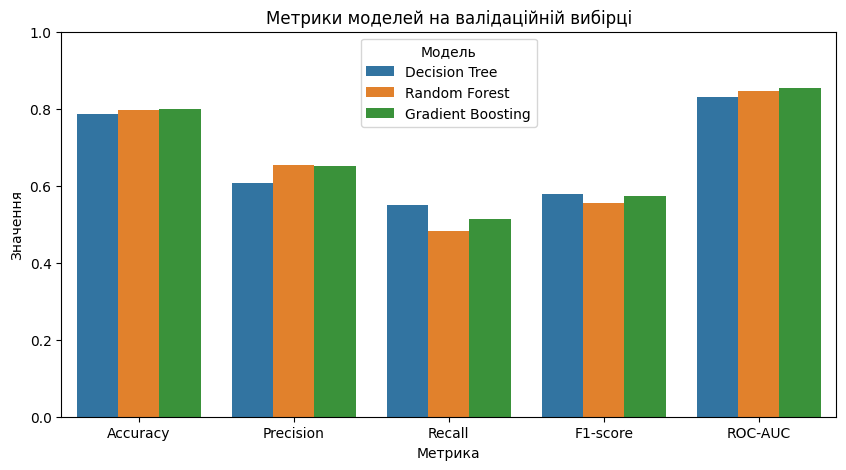

In [22]:
val_table = results_table[results_table["Вибірка"] == "Validation"]

plot_data = val_table.melt(
    id_vars="Модель",
    value_vars=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    var_name="Метрика",
    value_name="Значення"
)

plt.figure(figsize=(10, 5))
sns.barplot(data=plot_data, x="Метрика", y="Значення", hue="Модель")
plt.title("Метрики моделей на валідаційній вибірці")
plt.ylim(0, 1)
plt.show()

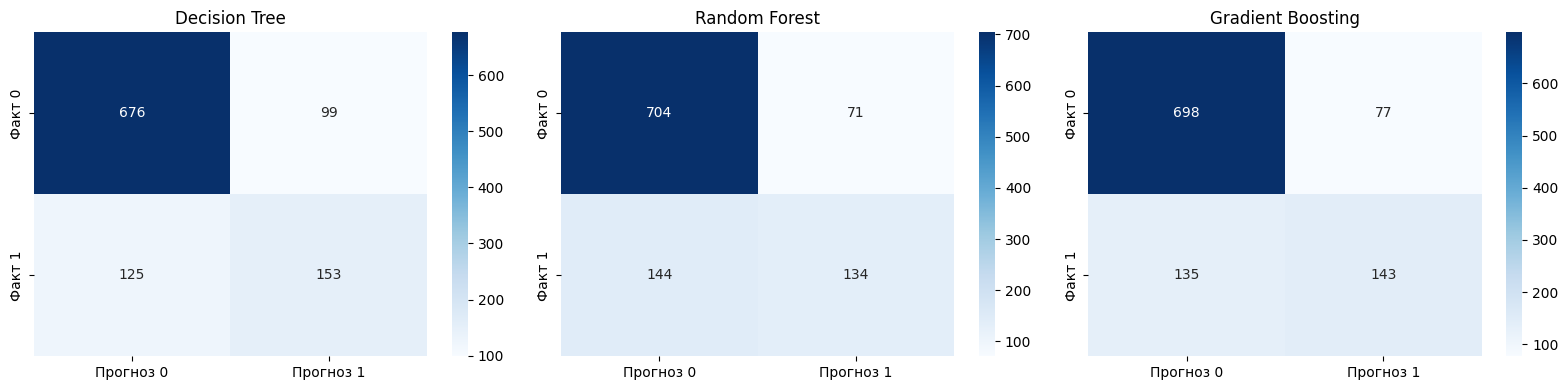

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, name in zip(axes, models.keys()):
    matrix = confusion_matrix(y_val, val_predictions[name])
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Прогноз 0", "Прогноз 1"], yticklabels=["Факт 0", "Факт 1"])
    ax.set_title(name)

plt.tight_layout()
plt.show()

На стовпчиковій діаграмі видно, що за Accuracy, Precision і ROC-AUC моделі йдуть у порядку дерево < ліс < бустинг, а за Recall і F1 дерево попереду.

Confusion matrix на валідації:
- **Decision Tree:** TN = 676, FP = 99, FN = 125, TP = 153;
- **Random Forest:** TN = 704, FP = 71, FN = 144, TP = 134;
- **Gradient Boosting:** TN = 698, FP = 77, FN = 135, TP = 143.

Дерево знаходить найбільше клієнтів, які йдуть (153 з 278), але й дає найбільше хибних тривог (99). Random Forest навпаки: найменше хибних тривог (71), але пропускає найбільше клієнтів класу 1 (144). Gradient Boosting посередині.

## 14. Feature importance

In [24]:
importance_df = pd.DataFrame({
    "Ознака": X_train_ready.columns,
    "Decision Tree": best_tree.feature_importances_,
    "Random Forest": best_rf.feature_importances_,
    "Gradient Boosting": best_gb.feature_importances_
})

print("Ознак з нульовою важливістю:")
print((importance_df[["Decision Tree", "Random Forest", "Gradient Boosting"]] == 0).sum())

Ознак з нульовою важливістю:
Decision Tree        31
Random Forest         0
Gradient Boosting    16
dtype: int64


## 15. Найважливіші ознаки та узгодженість рангів

In [25]:
for model_name in ["Decision Tree", "Random Forest", "Gradient Boosting"]:
    importance_df["Ранг " + model_name] = importance_df[model_name].rank(ascending=False, method="min").astype(int)

importance_df["Середня важливість"] = importance_df[["Decision Tree", "Random Forest", "Gradient Boosting"]].mean(axis=1)

top_features = importance_df.sort_values("Середня важливість", ascending=False).head(15)
top_features.round(4)

,Ознака,Decision Tree,Random Forest,Gradient Boosting,Ранг Decision Tree,Ранг Random Forest,Ранг Gradient Boosting,Середня важливість
36,Contract_Month-to-month,0.5052,0.0694,0.3311,1,4,1,0.3019
1,tenure,0.1827,0.1494,0.1837,2,1,2,0.1719
16,InternetService_Fiber optic,0.1519,0.0544,0.1280,3,5,3,0.1114
3,TotalCharges,0.0388,0.1259,0.0742,5,2,5,0.0797
2,MonthlyCharges,0.0495,0.0911,0.0802,4,3,4,0.0736
18,OnlineSecurity_No,0.0209,0.0347,0.0574,6,8,6,0.0377
27,TechSupport_No,0.0000,0.0403,0.0485,15,6,7,0.0296
43,PaymentMethod_Electronic check,0.0113,0.0371,0.0374,8,7,8,0.0286
38,Contract_Two year,0.0000,0.0321,0.0079,15,9,11,0.0133
21,OnlineBackup_No,0.0000,0.0188,0.0102,15,10,9,0.0097


In [26]:
rank_columns = ["Ранг Decision Tree", "Ранг Random Forest", "Ранг Gradient Boosting"]

print("Кореляція рангів ознак (Spearman):")
importance_df[rank_columns].corr(method="spearman").round(3)

Кореляція рангів ознак (Spearman):


,Ранг Decision Tree,Ранг Random Forest,Ранг Gradient Boosting
Ранг Decision Tree,1.000,0.508,0.560
Ранг Random Forest,0.508,1.000,0.637
Ранг Gradient Boosting,0.560,0.637,1.000


Дерево глибини 5 використовує лише 14 ознак з 45, у решти 31 важливість 0. Random Forest використовує всі 45 ознак, Gradient Boosting 29.

За середньою важливістю найважливіші ознаки: `Contract_Month-to-month` (0.302), `tenure` (0.172), `InternetService_Fiber optic` (0.111), `TotalCharges` (0.080), `MonthlyCharges` (0.074), далі `OnlineSecurity_No`, `TechSupport_No`, `PaymentMethod_Electronic check`. **П'ятірка найважливіших ознак однакова в усіх трьох моделях**, змінюється лише порядок. Дерево вкладає половину всієї важливості (0.505) в одну ознаку `Contract_Month-to-month`, бо саме за нею воно робить перше розбиття. Random Forest розподіляє важливість рівномірніше.

Кореляція рангів (Spearman) помірна: дерево і ліс 0.508, дерево і бустинг 0.560, ліс і бустинг 0.637. Тобто моделі погоджуються щодо головних ознак, а розбіжності в основному в «хвості» малокорисних ознак (у дерева 31 ознака має однаковий нульовий ранг).

## 16. Графік важливості ознак Random Forest

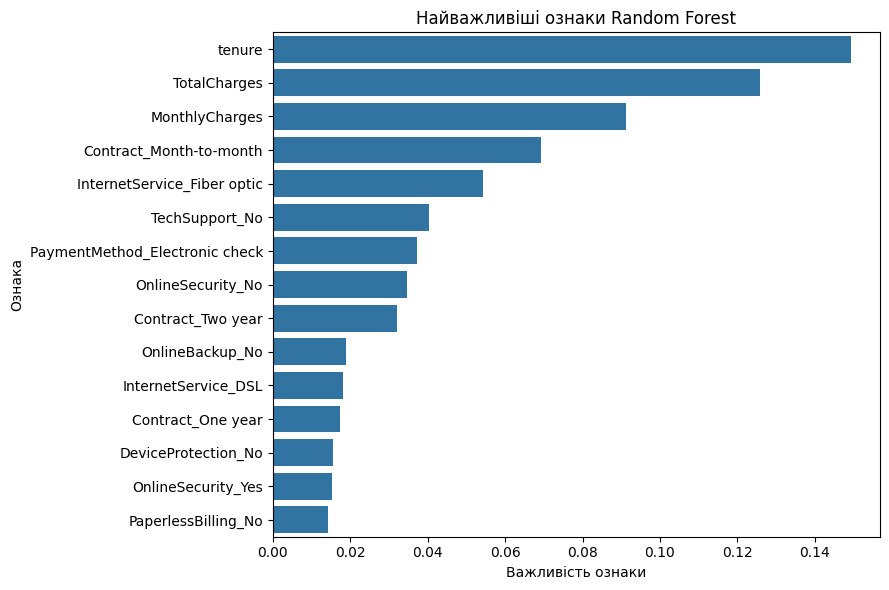

In [27]:
rf_top = importance_df.sort_values("Random Forest", ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(data=rf_top, x="Random Forest", y="Ознака")
plt.title("Найважливіші ознаки Random Forest")
plt.xlabel("Важливість ознаки")
plt.tight_layout()
plt.show()

У Random Forest на першому місці `tenure` (0.149), далі `TotalCharges` (0.126), `MonthlyCharges` (0.091), `Contract_Month-to-month` (0.069) і `InternetService_Fiber optic` (0.054). Ліс вище оцінює неперервні числові ознаки, бо в них багато можливих порогів для розбиття, і вони частіше потрапляють у дерева. Загальна картина логічна: частіше йдуть нові клієнти з помісячним контрактом, оптоволоконним інтернетом, без техпідтримки та онлайн-захисту, які платять електронним чеком. Це узгоджується з графіком контрактів з ЛР1. Але важливість ознаки показує лише те, як модель її використовує, а не те, що ознака є причиною відтоку.

## 17. Порівняння одиночного дерева та ансамблів

In [28]:
from sklearn.base import clone

rf_leaves = 0
for tree in best_rf.estimators_:
    rf_leaves = rf_leaves + tree.get_n_leaves()

gb_leaves = 0
for tree in best_gb.estimators_[:, 0]:
    gb_leaves = gb_leaves + tree.get_n_leaves()

complexity = {
    "Decision Tree": (1, best_tree.get_n_leaves()),
    "Random Forest": (best_rf.n_estimators, rf_leaves),
    "Gradient Boosting": (best_gb.n_estimators, gb_leaves)
}

compare_table = []

for name, model in models.items():
    new_model = clone(model)

    start = time.time()
    new_model.fit(X_train_ready, y_train)
    fit_time = time.time() - start

    start = time.time()
    new_model.predict(X_val_ready)
    predict_time = time.time() - start

    f1_train = results_table.loc[(results_table["Модель"] == name) & (results_table["Вибірка"] == "Train"), "F1-score"].iloc[0]
    f1_val = results_table.loc[(results_table["Модель"] == name) & (results_table["Вибірка"] == "Validation"), "F1-score"].iloc[0]

    compare_table.append({
        "Модель": name,
        "F1 val": f1_val,
        "F1 train - val": f1_train - f1_val,
        "Кількість дерев": complexity[name][0],
        "Усього листків": complexity[name][1],
        "Час навчання, с": fit_time,
        "Час прогнозу, с": predict_time
    })

pd.DataFrame(compare_table).round(3)

,Модель,F1 val,F1 train - val,Кількість дерев,Усього листків,"Час навчання, с","Час прогнозу, с"
0,Decision Tree,0.577,0.03,1,31,0.015,0.001
1,Random Forest,0.555,0.19,100,37147,0.167,0.027
2,Gradient Boosting,0.574,0.06,200,794,1.552,0.005


Порівняння за критеріями методички (час залежить від комп'ютера, важливе співвідношення):
- **Якість прогнозування:** за F1 дерево (0.577) і бустинг (0.574) практично рівні, ліс слабший (0.555). За ROC-AUC ансамблі кращі (0.853 і 0.847 проти 0.830).
- **Стійкість до перенавчання:** без обмежень дерево і ліс сильно перенавчаються (F1 train близько 1). Після підбору параметрів різниця F1 train - val у дерева 0.03, у бустингу 0.06, у лісу 0.19. Ліс з глибиною 10 найбільше підлаштовується під train.
- **Складність:** дерево - це 1 дерево з 31 листком; ліс - 100 дерев, разом 37147 листків; бустинг - 200 неглибоких дерев, разом 794 листки.
- **Інтерпретованість:** дерево можна намалювати і прочитати як набір правил «якщо ... то ...». Ансамбль з сотень дерев так прочитати неможливо, лишається тільки feature importance.
- **Час:** дерево навчається приблизно за 0.015 с, ліс за 0.17 с (дерева будуються паралельно, `n_jobs=-1`), бустинг найдовше, близько 1.5 с, бо дерева будуються строго по черзі. Прогноз найдовший у лісу (0.027 с), бо треба пройти через 100 глибоких дерев.

## 18. Вибір найкращої моделі та оцінювання на тестовій вибірці

За головним критерієм, F1-score на валідації, найкращою є **Decision Tree з `max_depth = 5`** (F1 0.577). Gradient Boosting відстає лише на 0.003 (це приблизно один об'єкт), а за ROC-AUC і Precision він кращий. Тому вибір між ними фактично визначають інші критерії. Дерево при майже однаковому F1 має найменше перенавчання (0.03), найпростіше (31 листок), навчається і прогнозує найшвидше і повністю інтерпретоване. Якщо ж для задачі важливіше правильно ранжувати клієнтів за ймовірністю відтоку (ROC-AUC), доцільніше було б взяти Gradient Boosting.

Обрану модель перенавчаємо на об'єднаних train і validation і один раз оцінюємо на test.

In [29]:
best_name = val_table.loc[val_table["F1-score"].idxmax(), "Модель"]
final_model = clone(models[best_name])

X_train_full = pd.concat([X_train_ready, X_val_ready])
y_train_full = pd.concat([y_train, y_val])

final_model.fit(X_train_full, y_train_full)

test_pred = final_model.predict(X_test_ready)
test_prob = final_model.predict_proba(X_test_ready)[:, 1]

print("Обрана модель:", best_name)
print("Розмір train + val:", X_train_full.shape)

final_results = pd.DataFrame([{
    "Модель": best_name,
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(y_test, test_pred),
    "Recall": recall_score(y_test, test_pred),
    "F1-score": f1_score(y_test, test_pred),
    "ROC-AUC": roc_auc_score(y_test, test_prob)
}])
final_results.round(3)

Обрана модель: Decision Tree
Розмір train + val: (5967, 45)


,Модель,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision Tree,0.792,0.605,0.62,0.612,0.826


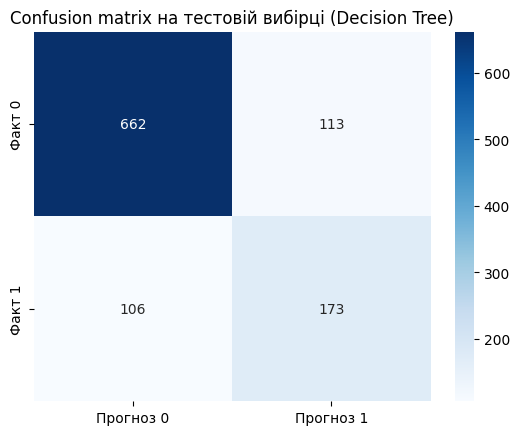

In [30]:
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Прогноз 0", "Прогноз 1"], yticklabels=["Факт 0", "Факт 1"])
plt.title("Confusion matrix на тестовій вибірці (" + best_name + ")")
plt.show()

На тестовій вибірці дерево глибини 5, перенавчене на 5967 об'єктах, показало Accuracy 0.792, Precision 0.605, Recall 0.620, F1-score 0.612 і ROC-AUC 0.826. Confusion matrix: TN = 662, FP = 113, FN = 106, TP = 173, тобто з 279 клієнтів, які пішли, модель знайшла 173. F1 на тесті навіть вищий, ніж на валідації (0.577). Це пояснюється тим, що модель навчена на більшій вибірці, а також тим, що окреме дерево досить чутливе до того, які саме об'єкти потрапили у вибірку. Для порівняння: найкраща модель ЛР3 (Logistic Regression) на тій самій тестовій вибірці мала F1 0.603 і ROC-AUC 0.839, тобто дерево дало близький F1 і трохи гірший ROC-AUC.

## 19. Висновки

- **Порівняння моделей.** Після підбору параметрів усі три моделі показали близьку якість на валідації: F1 0.555-0.577, ROC-AUC 0.830-0.853. За F1 найкраще дерево глибини 5 (0.577), майже на рівні Gradient Boosting (0.574), Random Forest слабший (0.555). За ROC-AUC, Accuracy і Precision кращі ансамблі, особливо Gradient Boosting (ROC-AUC 0.853).
- **Вплив ансамблевого навчання.** Ансамблі краще ранжують клієнтів за ймовірністю відтоку (вищий ROC-AUC) і роблять менше хибних тривог, але на цих даних не дали суттєвого виграшу в F1. Межа між класами тут відносно проста (у ЛР3 найкращою була лінійна модель), тому навіть невелике дерево ловить головні закономірності. Ансамблі також «обережніші» і знаходять менше клієнтів класу 1 при порозі 0.5.
- **Роль гіперпараметрів.** Для дерева і лісу вирішальна глибина: без обмеження обидві моделі перенавчаються (F1 на train близько 1, на val близько 0.50), а обмеження глибини до 5 (дерево) чи 10 (ліс) дає найкращий результат. Для бустингу важливі кількість дерев і learning_rate: більше дерев і більший крок дали кращий F1 (200 дерев, 0.1). `min_samples_split` і `min_samples_leaf` при обмеженій глибині майже не впливали.
- **Найважливіші ознаки.** У всіх трьох моделях п'ятірка однакова: `Contract_Month-to-month`, `tenure`, `InternetService_Fiber optic`, `TotalCharges`, `MonthlyCharges`. Тобто відтік найбільше пов'язаний з типом контракту, тривалістю обслуговування і платежами.
- **Найбільш доцільна модель.** За обраним критерієм (F1) - Decision Tree з `max_depth = 5`: при майже такій самій якості, як у Gradient Boosting, вона найпростіша, найшвидша, найменше перенавчається і її можна інтерпретувати як набір правил. На тесті вона показала F1 0.612 і ROC-AUC 0.826. Якщо ж потрібна найкраща оцінка ймовірності відтоку, варто обрати Gradient Boosting.